# MD analysis: Cm_12 compared with evenMH

Compare RNA12 with Cm at position 12 (`Cm_12`, red) with the `evenMH` reference (blue). The selected ranges are around SL 12: rows 12–15 for rise, twist, inclination, and radius, and rows 12–16 for propeller. Input files are read from `../MD_data/RNA12` and `../MD_data/RNA_evenMH` relative to this notebook. The imported and processed arrays are kept in memory; no data files are saved.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

names = ["evenMH", "Cm_12"]
colors = {"evenMH": "blue", "Cm_12": "red"}
parameters = ["rise", "twist", "inclination", "radius", "propeller"]
parameter_rows = slice(11, 15)  # MATLAB rows 12:15
propeller_rows = slice(11, 16)  # MATLAB rows 12:16

data_folders = {
    "Cm_12": Path("../MD_data/RNA12"),
    "evenMH": Path("../MD_data/RNA_evenMH"),
}
file_prefixes = {"Cm_12": "RNA12_Cm", "evenMH": "RNA_evenMH"}

raw_data = {
    name: {
        parameter: np.loadtxt(
            data_folders[name] / f"{file_prefixes[name]}_{parameter}.txt"
        )
        for parameter in parameters
    }
    for name in names
}

In [2]:
data = {}

for name in names:
    data[name] = {}
    for parameter in parameters:
        rows = propeller_rows if parameter == "propeller" else parameter_rows
        data[name][parameter] = raw_data[name][parameter][rows, :]

    bad_frames = np.zeros(data[name]["rise"].shape[1], dtype=bool)
    for parameter in parameters:
        bad_frames |= (data[name][parameter] == 99.99).any(axis=0)
        bad_frames |= (data[name][parameter] < -100).any(axis=0)

    for parameter in parameters:
        data[name][parameter] = np.mean(
            data[name][parameter][:, ~bad_frames], axis=0
        )

common_frames = min(
    len(data[name][parameter])
    for name in names
    for parameter in ["rise", "twist", "inclination", "propeller"]
)

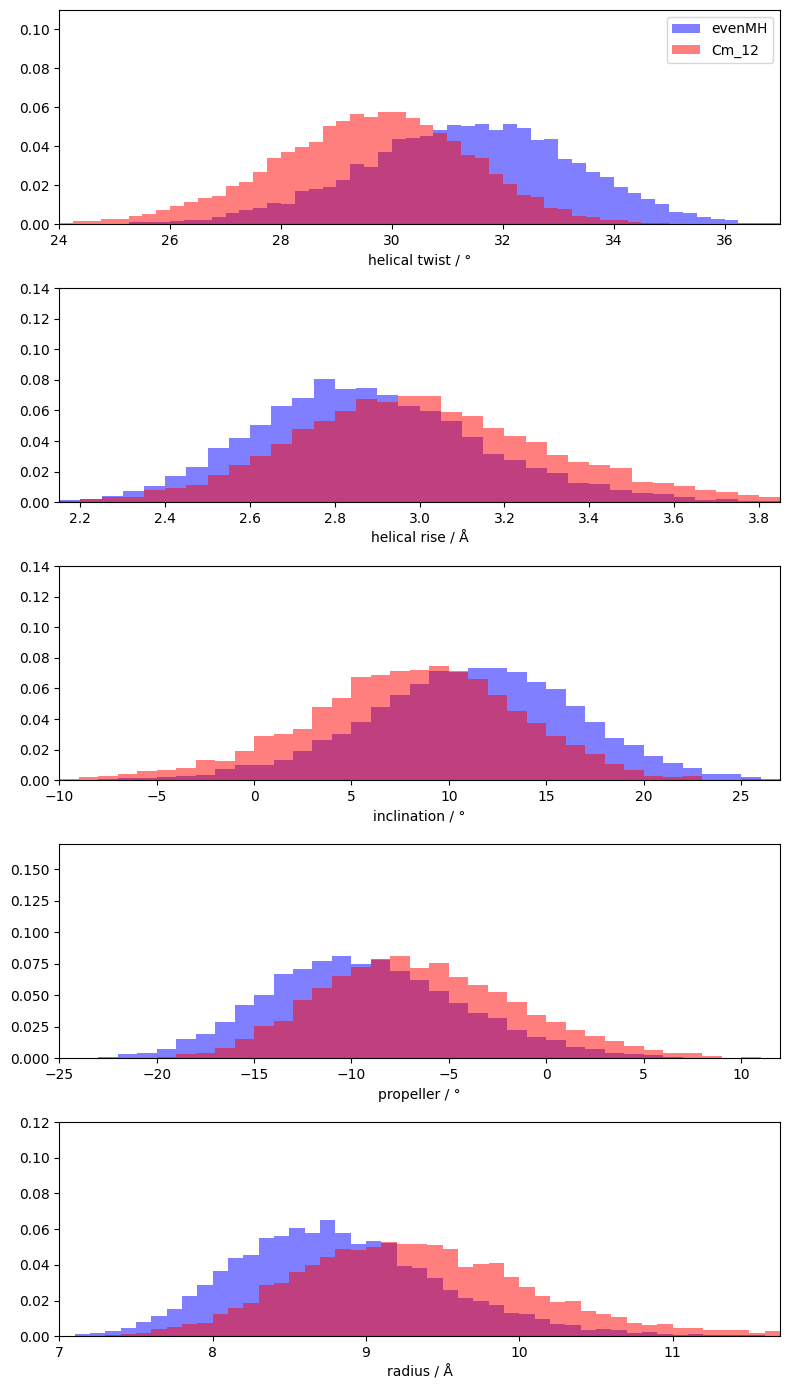

In [3]:
histogram_plots = [
    ("twist", "helical twist / °", 0.25, (24, 37), (0, 0.11)),
    ("rise", "helical rise / Å", 0.05, (2.15, 3.85), (0, 0.14)),
    ("inclination", "inclination / °", 1, (-10, 27), (0, 0.14)),
    ("propeller", "propeller / °", 1, (-25, 12), (0, 0.17)),
    ("radius", "radius / Å", 0.1, (7, 11.7), (0, 0.12)),
]

fig, axes = plt.subplots(5, 1, figsize=(8, 14))
alpha = 0.5

for axis, (parameter, label, bin_width, x_limits, y_limits) in zip(axes, histogram_plots):
    bins = np.arange(x_limits[0], x_limits[1] + bin_width, bin_width)
    for name in names:
        values = data[name][parameter]
        if parameter != "radius":
            values = values[:common_frames]
        axis.hist(
            values,
            bins=bins,
            weights=np.ones(len(values)) / len(values),
            color=colors[name],
            alpha=alpha,
            label=name,
        )
    axis.set_xlabel(label)
    axis.set_xlim(x_limits)
    axis.set_ylim(y_limits)

axes[0].legend()
plt.tight_layout()
plt.show()

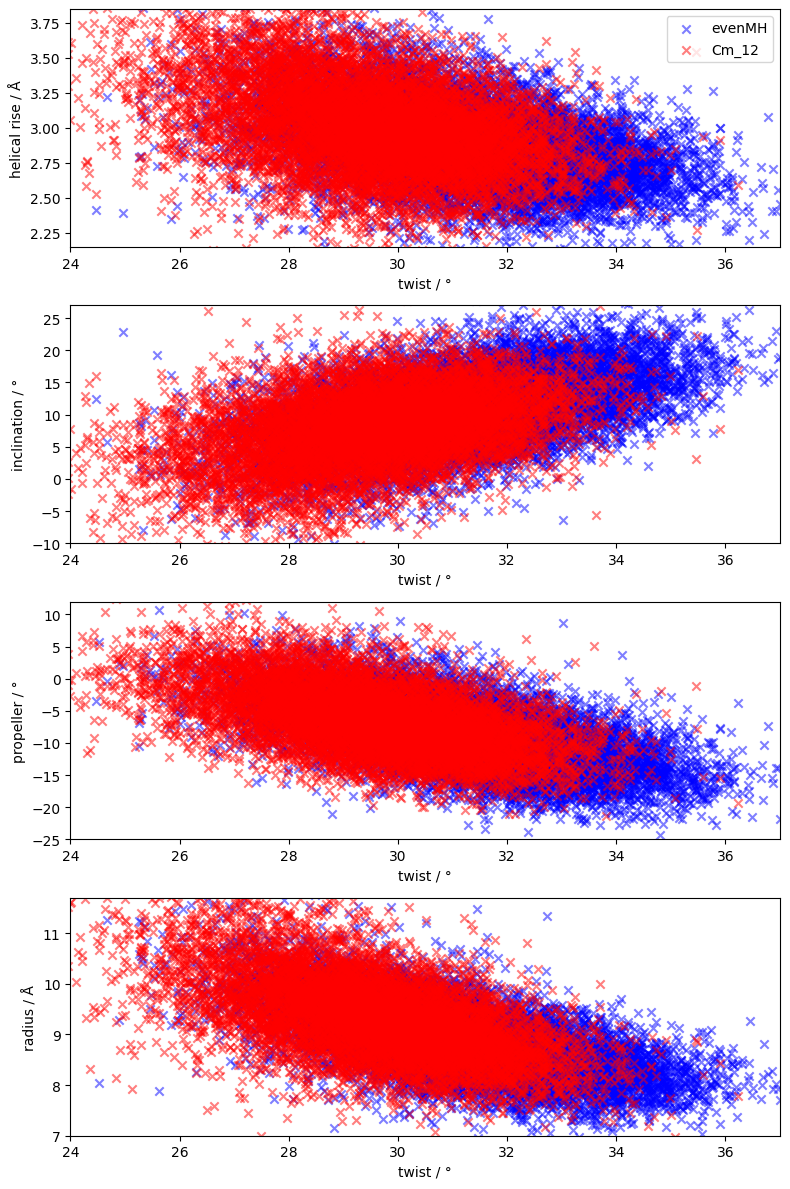

In [4]:
correlation_plots = [
    ("rise", "helical rise / Å", (2.15, 3.85)),
    ("inclination", "inclination / °", (-10, 27)),
    ("propeller", "propeller / °", (-25, 12)),
    ("radius", "radius / Å", (7, 11.7)),
]

fig, axes = plt.subplots(4, 1, figsize=(8, 12))
alpha = 0.5

for axis, (parameter, label, y_limits) in zip(axes, correlation_plots):
    for name in names:
        frame_count = len(data[name]["radius"]) if parameter == "radius" else common_frames
        axis.scatter(
            data[name]["twist"][:frame_count],
            data[name][parameter][:frame_count],
            color=colors[name],
            alpha=alpha,
            marker="x",
            label=name,
        )
    axis.set_xlim(24, 37)
    axis.set_ylim(y_limits)
    axis.set_ylabel(label)
    axis.set_xlabel("twist / °")

axes[0].legend()
plt.tight_layout()
plt.show()